In [1]:
import sys
sys.path.append("..")
from src.metrics import percentile_quadrant
from src.viz import plot_quadrant_scatter
from src.db import append_note
import pandas as pd

In [2]:
df_analysis = pd.read_csv("../data/processed/analysis_base.csv")

Số laptop 'click nhiều nhưng battery_density kém': 5


,id,name,interest_score,battery_density,is_gaming_laptop
11,12,Lenovo LOQ 15IAX9,3914,0.031132,True
30,31,Lenovo Legion Slim 5 16AHP9,2572,0.034783,True
31,32,Lenovo LOQ 15ARP9 83JC0000US,4216,0.025000,True
43,44,ASUS Gaming VivoBook K3605ZF-RP634W,1621,0.027778,True
103,115,ASUS ROG Strix G16,2178,0.035239,True


Đã lưu: ../reports/figures\h9_quadrant_scatter.png


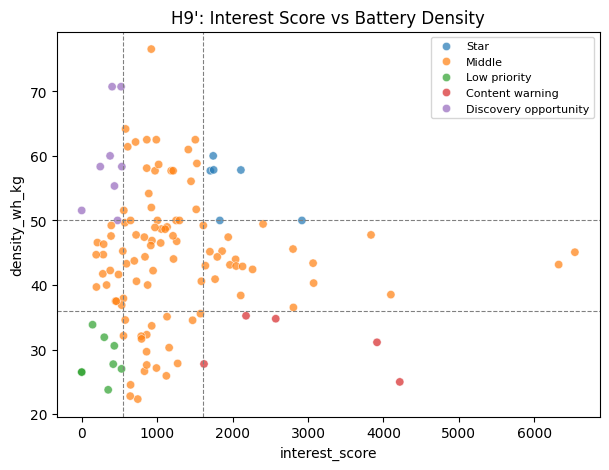

In [3]:
### H9': nhóm "click nhiều nhưng battery_density kém"
# Đã pivot từ office_battery_per_whr sang battery_density — xem quyết định ở notebook 02.
df_analysis["h9_group"] = percentile_quadrant(
    df_analysis, col_x="interest_score", col_y="battery_density",
    upper_pct=0.75, lower_pct=0.25
)
df_h9_risk = df_analysis[df_analysis["h9_group"] == "top_x_bottom_y"]
print(f"Số laptop 'click nhiều nhưng battery_density kém': {len(df_h9_risk)}")
display(df_h9_risk[["id", "name", "interest_score", "battery_density", "is_gaming_laptop"]])

H9_LABELS = {"top_x_top_y": "Star", "top_x_bottom_y": "Content warning",
             "bottom_x_top_y": "Discovery opportunity", "bottom_x_bottom_y": "Low priority",
             "middle": "Middle"}
df_plot = df_analysis.assign(density_wh_kg=df_analysis["battery_density"] * 1000,
                             group=df_analysis["h9_group"].map(H9_LABELS))
plot_quadrant_scatter(df_plot, "interest_score", "density_wh_kg", "group",
                      "H9': Interest Score vs Battery Density", "h9_quadrant_scatter.png",
                      x_lines=[df_plot["interest_score"].quantile(q) for q in (0.25, 0.75)],
                      y_lines=[df_plot["density_wh_kg"].quantile(q) for q in (0.25, 0.75)])


In [4]:
### H9' có độc lập với xu hướng chung của gaming không?
gaming_density_stats = df_analysis.loc[df_analysis["is_gaming_laptop"] == True, "battery_density"].describe()
print("Thống kê battery_density của TOÀN BỘ laptop gaming:")
print(gaming_density_stats)

print("\nbattery_density của 5 laptop trong nhóm H9':")
print(df_h9_risk["battery_density"].describe())

# So sánh: 5 laptop H9' có nằm ở percentile thấp NGAY CẢ SO VỚI riêng nhóm gaming không?
gaming_only = df_analysis[df_analysis["is_gaming_laptop"] == True].copy()
gaming_only["density_percentile_within_gaming"] = gaming_only["battery_density"].rank(pct=True)
h9_within_gaming = gaming_only[gaming_only["id"].isin(df_h9_risk["id"])]
display(h9_within_gaming[["id", "name", "battery_density", "density_percentile_within_gaming", "interest_score"]])

Thống kê battery_density của TOÀN BỘ laptop gaming:
count    47.000000
mean      0.037152
std       0.008991
min       0.022800
25%       0.029081
50%       0.036885
75%       0.043634
max       0.058333
Name: battery_density, dtype: float64

battery_density của 5 laptop trong nhóm H9':
count    5.000000
mean     0.030786
std      0.004429
min      0.025000
25%      0.027778
50%      0.031132
75%      0.034783
max      0.035239
Name: battery_density, dtype: float64


,id,name,battery_density,density_percentile_within_gaming,interest_score
11,12,Lenovo LOQ 15IAX9,0.031132,0.297872,3914
30,31,Lenovo Legion Slim 5 16AHP9,0.034783,0.468085,2572
31,32,Lenovo LOQ 15ARP9 83JC0000US,0.025000,0.085106,4216
43,44,ASUS Gaming VivoBook K3605ZF-RP634W,0.027778,0.234043,1621
103,115,ASUS ROG Strix G16,0.035239,0.489362,2178


In [5]:
### [Giai đoạn 3 - D, đính chính] H9' là hỗn hợp giữa hệ quả H1' và tín hiệu độc lập
h9_confound_note = """
## [Giai đoạn 3 - Trục 3] Đính chính: H9' không hoàn toàn độc lập với H1'

Kiểm tra density_percentile_within_gaming của 5 laptop trong nhóm H9':
- Lenovo LOQ 15ARP9 83JC0000US: percentile 8.5% trong nhóm gaming -> outlier THẬT (độc lập với H1')
- ASUS Gaming VivoBook K3605ZF-RP634W: percentile 23.4% -> outlier THẬT (độc lập với H1')
- Lenovo LOQ 15IAX9: percentile 29.8% -> hơi thấp, không rõ ràng
- Lenovo Legion Slim 5 16AHP9: percentile 46.8% -> BÌNH THƯỜNG trong nhóm gaming
- ASUS ROG Strix G16: percentile 48.9% -> BÌNH THƯỜNG trong nhóm gaming

**Kết luận:** H9' (dùng ngưỡng percentile trên TOÀN population) là hỗn hợp 2 hiệu ứng:
(1) hệ quả trực tiếp của H1' — gaming vốn có battery_density thấp hơn văn phòng nói chung,
nên dễ lọt vào "bottom 25% toàn population" dù bản thân không bất thường trong phân khúc gaming
(trường hợp Legion Slim 5, ROG Strix G16); (2) tín hiệu ĐỘC LẬP thật — 2/5 laptop
(Lenovo LOQ 15ARP9, ASUS VivoBook K3605ZF) có battery_density thấp bất thường NGAY CẢ so với
riêng phân khúc gaming, đây mới là phát hiện content/affiliate đáng giá nhất.

**Khuyến nghị cho Giai đoạn 4:** khi viết insight, nêu 2 laptop outlier thật (LOQ 15ARP9,
VivoBook K3605ZF) làm ví dụ chính cho "cơ hội cảnh báo nội dung", KHÔNG trình bày cả 5 laptop
như bằng chứng ngang hàng, để tránh overclaim. Có thể nhắc ngắn gọn 3 laptop còn lại là phản ánh
xu hướng chung của H1' hơn là phát hiện riêng.
"""
append_note(h9_confound_note)

In [6]:
### Sensitivity check với nhiều ngưỡng percentile
sensitivity_results = []
for pct in [0.20, 0.25, 0.30]:
    grp = percentile_quadrant(df_analysis, "interest_score", "battery_density",
                               upper_pct=1 - pct, lower_pct=pct)
    n = (grp == "top_x_bottom_y").sum()
    sensitivity_results.append({"percentile_threshold": pct, "n_laptops_flagged": n})
df_sensitivity = pd.DataFrame(sensitivity_results)
display(df_sensitivity)

note = f"""
## [Giai đoạn 3 - Trục 3] H9' — Kết quả

Số laptop 'click nhiều nhưng battery_density kém' (ngưỡng 25/75): {len(df_h9_risk)}
Danh sách: cột h9_quadrant/opportunity_type trong data/processed/dashboard_laptop.csv

Sensitivity check theo ngưỡng percentile:
{df_sensitivity.to_markdown(index=False)}

Lưu ý: H8 (backlog, Spearman office_battery_result_minutes vs interest_score) bị loại khỏi
phạm vi phân tích do office_battery_result_minutes chỉ có n=1 dòng dữ liệu (xem quyết định
pivot ở notebook 02) — không đủ điều kiện chạy bất kỳ kiểm định thống kê nào.
"""
append_note(note)

,percentile_threshold,n_laptops_flagged
0,0.20,2
1,0.25,5
2,0.30,9


In [7]:
### Ghi tổng kết Giai đoạn 3 vào project_notes.md
summary = """
## [Giai đoạn 3] Tổng kết

Đã hoàn thành kiểm định cho 3 insight chính: H1' (Trục 1), H5 (Trục 2), H9 (Trục 3).
Mỗi kiểm định đều có effect size + p-value, ghi chú correlation != causation, và phần rủi ro/giới hạn.
Output: data/processed/dashboard_laptop.csv (golden_group, h9_quadrant),
reports/figures/*.png. Sẵn sàng chuyển sang Giai đoạn 4: đúc kết insight & đề xuất kinh doanh.
"""
append_note(summary)

In [8]:
### [Giai đoạn 4] Đúc kết insight & đề xuất kinh doanh
stage4_note = """
## [Giai đoạn 4] Đúc kết insight & đề xuất kinh doanh

Đã hoàn thành reports/insight_summary.md với 3 insight chính, mỗi insight có: pattern (dựa
đúng kết quả thống kê Giai đoạn 3, đã đính chính chiều H5 và tách bạch H9'), biểu đồ minh họa
nhúng trực tiếp, quyết định kinh doanh theo từng đơn vị (đối chiếu bảng bối cảnh mục 1.1),
ước tính tác động có công thức/giả định rõ ràng, và phần rủi ro/giới hạn.

Bảng ánh xạ Insight -> Đơn vị:
- Insight 1 (Golden Ratio ultrabook) -> Nội dung/Review (chính), Sản phẩm/UX (liên quan)
- Insight 2 (Văn phòng > Gaming interest, NGƯỢC giả thuyết ban đầu) -> Sản phẩm/UX (chính), Affiliate (liên quan)
- Insight 3 (2 model gaming hot nhưng pin kém) -> Nội dung/Review (chính), Affiliate (liên quan)

Đã bổ sung ghi chú đạo đức dữ liệu: mọi số liệu trong insight_summary.md đều đã tổng hợp theo
laptop_model_id, không xuất user_psuedo_id/session_id gốc ra báo cáo.

Output: reports/insight_summary.md (kèm ảnh từ reports/figures/). Sẵn sàng chuyển sang
Giai đoạn 5 (Dashboard) và Giai đoạn 6 (Deliverable & Documentation chuẩn cho CV).
"""
append_note(stage4_note)